1. Import

In [15]:
import numpy as np
from pathlib import Path
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
pd.set_option("display.max_columns", None)
sns.set_theme()

2. Project Paths

In [16]:
PROJECT_ROOT = Path.cwd().parent
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
SPLITS_DIR = PROJECT_ROOT / "data" / "splits"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
SPLITS_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Raw Data Directory:", RAW_DIR)
print("CSV files:", list(RAW_DIR.glob("*.csv")))

Project root: /Users/macbookpro/PycharmProjects/Techcart_ai
Raw Data Directory: /Users/macbookpro/PycharmProjects/Techcart_ai/data/raw
CSV files: [PosixPath('/Users/macbookpro/PycharmProjects/Techcart_ai/data/raw/products.csv'), PosixPath('/Users/macbookpro/PycharmProjects/Techcart_ai/data/raw/reviews.csv'), PosixPath('/Users/macbookpro/PycharmProjects/Techcart_ai/data/raw/interactions.csv')]


3. Load Dataset

In [17]:
DATA_PATH = RAW_DIR / "products.csv"
if not DATA_PATH.exists():
    csv_files = list(RAW_DIR.glob("*.csv"))

    if len(csv_files) == 1:
        DATA_PATH = csv_files[0]
    else:
        raise FileNotFoundError(f"Could not find any CSV files in {RAW_DIR}")

df = pd.read_csv(DATA_PATH, sep="\t")
print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (200, 7)


,product_id,name,category,brand,price,stock,rating
0,1,MacBook Pro M4 14,Laptop,Apple,10677.59,10.0,4.7
1,2,RTX 5070 Ti 16GB,GPU,NVIDIA,771.27,13.0,4.9
2,3,Core Ultra 5 245K,CPU,Intel,323.46,12.0,4.3
3,4,16GB DDR5-5600,RAM,Kingston,50.02,47.0,4.2
4,5,27in 4K OLED 240Hz,Monitor,ASUS,891.3,5.0,4.7


4. Inspect Data

In [18]:
print("Columns:", df.columns.tolist())
print("\nData Types:", df.dtypes)
print("\nMissing Values:", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
display(df.describe(include="all").T)

Columns: ['product_id', 'name', 'category', 'brand', 'price', 'stock', 'rating']

Data Types: product_id      int64
name           object
category       object
brand          object
price          object
stock         float64
rating        float64
dtype: object

Missing Values: product_id    0
name          0
category      0
brand         3
price         2
stock         3
rating        2
dtype: int64

Duplicate rows: 4


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
product_id,200.0,NaN,NaN,NaN,97.94,56.760773,1.0,48.75,97.5,146.25,196.0
name,200,45,2TB SN850X,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,200,11,SSD,36,NaN,NaN,NaN,NaN,NaN,NaN,NaN
brand,197,26,AMD,31,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,198,191,166.92,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
stock,197.0,NaN,NaN,NaN,20.238579,14.650658,3.0,10.0,16.0,26.0,101.0
rating,198.0,NaN,NaN,NaN,4.685354,0.182308,4.2,4.6,4.7,4.8,6.0


5. Clean Dataset

In [19]:
REQUIRED_COLUMNS = ["product_id", "name", "category", "brand", "price", "stock", "rating"]
missing_columns = [
    col for col in REQUIRED_COLUMNS if col not in df.columns]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")
    df = df[REQUIRED_COLUMNS].copy()

df = df.drop_duplicates()

for col in ["price", "stock", "rating"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

for col in ["product_id", "name", "category", "brand"]:
    df[col] = df[col].astype("string").str.strip()
    df[col] = df[col].replace("", pd.NA)

df = df.dropna(subset=["category"]).copy()

df.loc[df["price"] < 0, "price"] = np.nan
df.loc[df["stock"] < 0, "stock"] = np.nan

df.loc[
    (df["rating"] < 0) | (df["rating"] > 5),
    "rating"
] = np.nan

print("Cleaned shape:", df.shape)
display(df.head())
display(df.isnull().sum())

Cleaned shape: (196, 7)


,product_id,name,category,brand,price,stock,rating
0,1,MacBook Pro M4 14,Laptop,Apple,10677.59,10.0,4.7
1,2,RTX 5070 Ti 16GB,GPU,NVIDIA,771.27,13.0,4.9
2,3,Core Ultra 5 245K,CPU,Intel,323.46,12.0,4.3
3,4,16GB DDR5-5600,RAM,Kingston,50.02,47.0,4.2
4,5,27in 4K OLED 240Hz,Monitor,ASUS,891.30,5.0,4.7


product_id    0
name          0
category      0
brand         3
price         5
stock         3
rating        3
dtype: int64

6. Exploratory Data Analysis (EDA)

In [20]:
print("Number of products:", len(df))
print("Number of categories:", df["category"].nunique())
print("Number of brands:", df["brand"].nunique())

display(df["category"].value_counts())
display(
    df.groupby("category")[["price", "stock", "rating"]]
      .median())

Number of products: 196
Number of categories: 11
Number of brands: 21


category
SSD            36
CPU            29
GPU            27
RAM            22
Case           16
Mouse          15
Monitor        14
Motherboard    12
PSU            11
Laptop          7
Headset         7
Name: count, dtype: Int64

,price,stock,rating
category,,,
CPU,347.600,16.0,4.70
Case,116.795,16.5,4.65
GPU,694.570,8.0,4.75
Headset,330.660,6.0,4.80
Laptop,1706.950,8.0,4.75
Monitor,662.295,7.5,4.65
Motherboard,194.030,13.0,4.70
Mouse,154.610,15.0,4.70
PSU,135.830,16.0,4.70


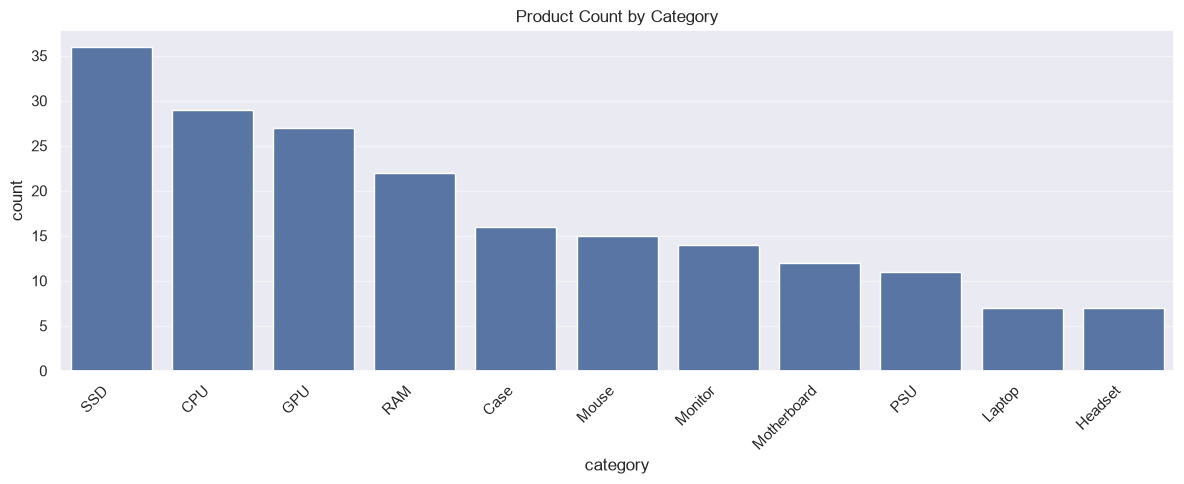

In [21]:
plt.figure(figsize=(12, 5))
sns.countplot(
    data=df,
    x="category",
    order=df["category"].value_counts().index)

plt.title("Product Count by Category")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

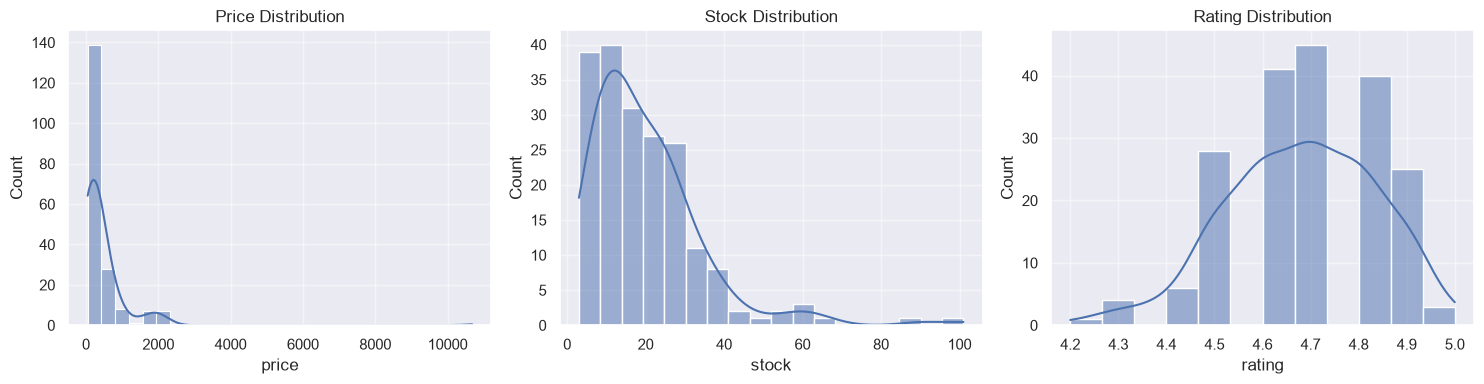

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(
    axes,
    ["price", "stock", "rating"]
):
    sns.histplot(data=df, x=col, kde=True, ax=ax)
    ax.set_title(f"{col.title()} Distribution")
plt.tight_layout()
plt.show()

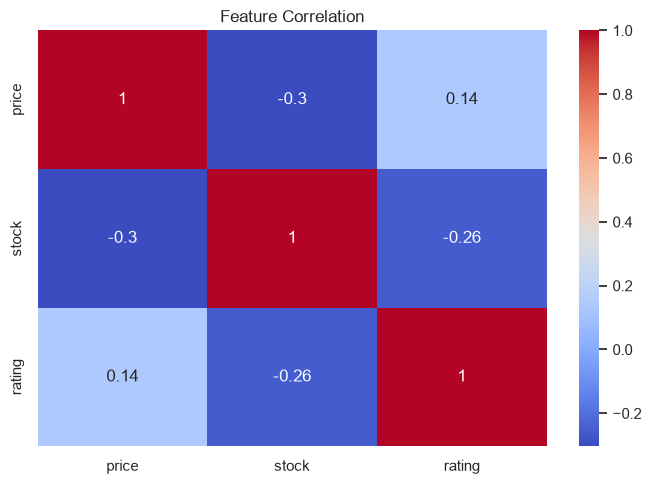

In [23]:
plt.figure(figsize=(7, 5))
sns.heatmap(
    df[["price", "stock", "rating"]].corr(),
    annot=True,
    cmap="coolwarm"
)
plt.title("Feature Correlation")
plt.tight_layout()
plt.show()

7. Select features and target

In [24]:
FEATURE_COLUMNS = [
    "brand",
    "price",
    "stock",
    "rating"
]

TARGET_COLUMN = "category"

model_df = df[
    FEATURE_COLUMNS + [TARGET_COLUMN]
].copy()

X = model_df[FEATURE_COLUMNS]
y = model_df[TARGET_COLUMN].astype(str)

print("X shape:", X.shape)
print("y shape:", y.shape)

display(model_df.head())

X shape: (196, 4)
y shape: (196,)


,brand,price,stock,rating,category
0,Apple,10677.59,10.0,4.7,Laptop
1,NVIDIA,771.27,13.0,4.9,GPU
2,Intel,323.46,12.0,4.3,CPU
3,Kingston,50.02,47.0,4.2,RAM
4,ASUS,891.30,5.0,4.7,Monitor


8. Split train, validation, test

In [25]:
# Use stratification only when there are enough examples
# in every class for the first split.
class_counts = y.value_counts()

stratify_y = (
    y
    if len(class_counts) > 1 and class_counts.min() >= 3
    else None
)

try:
    X_train, X_temp, y_train, y_temp = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
        stratify=stratify_y
    )
except ValueError:
    X_train, X_temp, y_train, y_temp = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42
    )

# Split the remaining 20% equally into validation and test.
temp_counts = y_temp.value_counts()

stratify_temp = (
    y_temp
    if len(temp_counts) > 1 and temp_counts.min() >= 2
    else None
)

try:
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp,
        y_temp,
        test_size=0.50,
        random_state=42,
        stratify=stratify_temp
    )
except ValueError:
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp,
        y_temp,
        test_size=0.50,
        random_state=42
    )

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

print("\nTraining categories:")
print(y_train.value_counts())

Train: (156, 4)
Validation: (20, 4)
Test: (20, 4)

Training categories:
category
SSD            29
CPU            23
GPU            21
RAM            17
Case           13
Mouse          12
Monitor        11
PSU             9
Motherboard     9
Headset         6
Laptop          6
Name: count, dtype: int64


9. Save processed data and splits

In [26]:
train_df = X_train.copy()
train_df[TARGET_COLUMN] = y_train

val_df = X_val.copy()
val_df[TARGET_COLUMN] = y_val

test_df = X_test.copy()
test_df[TARGET_COLUMN] = y_test

df.to_csv(
    PROCESSED_DIR / "products_cleaned.csv",
    index=False
)

train_df.to_csv(
    SPLITS_DIR / "train.csv",
    index=False
)

val_df.to_csv(
    SPLITS_DIR / "validation.csv",
    index=False
)

test_df.to_csv(
    SPLITS_DIR / "test.csv",
    index=False
)

print("Saved cleaned dataset and splits.")

Saved cleaned dataset and splits.
